In [100]:
import pandas as pd
import numpy as np

df = pd.read_parquet(
    "../data/processed/feature_engineered_sample.parquet"
)

print("Shape:", df.shape)
print("Unique products:", df["id"].nunique())
print("Date range:", df["date"].min(), "to", df["date"].max())

Shape: (1913000, 26)
Unique products: 1000
Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00


### Check the features and data quality

In [101]:
print("Duplicate product-day rows:", df.duplicated(["id", "date"]).sum())

print("\nMissing values:")
print(df[[
    "sales",
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]].isnull().sum())

print("\nNegative sales:", (df["sales"] < 0).sum())

Duplicate product-day rows: 0

Missing values:
sales                  0
lag_1               1000
lag_7               7000
lag_28             28000
rolling_mean_7      7000
rolling_mean_28    28000
dtype: int64

Negative sales: 0


### Created Time-Based Train/Test Split

##### converts the column to real dates and then sort, reset them 

In [102]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["date", "id"]).reset_index(drop=True)

###### We need to predict future demand using past data. So we'll split the data chronologically, not randomly.

In [103]:
test_days = 28
# For our initial experiment, we'll use the last 28 days as the test period.
unique_dates = sorted(df["date"].unique())

cutoff_date = unique_dates[-test_days]
#the oldest data becomes the training set, and the most recent 28 days become the test set.
train_df = df[df["date"] < cutoff_date].copy()
test_df = df[df["date"] >= cutoff_date].copy()

print("Training period:", train_df["date"].min(), "to", train_df["date"].max())
print("Testing period:", test_df["date"].min(), "to", test_df["date"].max())

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training period: 2011-01-29 00:00:00 to 2016-03-27 00:00:00
Testing period: 2016-03-28 00:00:00 to 2016-04-24 00:00:00
Training shape: (1885000, 26)
Testing shape: (28000, 26)


### For checking the split is clean or not 

In [104]:
print("Train/test overlap:", 
      train_df["date"].max() >= test_df["date"].min())
# no overlap between train and test
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("Products in training:", train_df["id"].nunique())
print("Products in testing:", test_df["id"].nunique())
# nunique() counts distinct values- unique products

Train/test overlap: False
Training rows: 1885000
Testing rows: 28000
Products in training: 1000
Products in testing: 1000


### SPLIT PERCENTAGE PROPORTION 

In [105]:
total_rows = len(train_df) + len(test_df)

train_percentage = (len(train_df) / total_rows) * 100
test_percentage = (len(test_df) / total_rows) * 100

print(f"Total rows: {total_rows:,}")
print(f"Training data: {len(train_df):,} ({train_percentage:.2f}%)")
print(f"Testing data:  {len(test_df):,} ({test_percentage:.2f}%)")

Total rows: 1,913,000
Training data: 1,885,000 (98.54%)
Testing data:  28,000 (1.46%)


### Visualize the split 

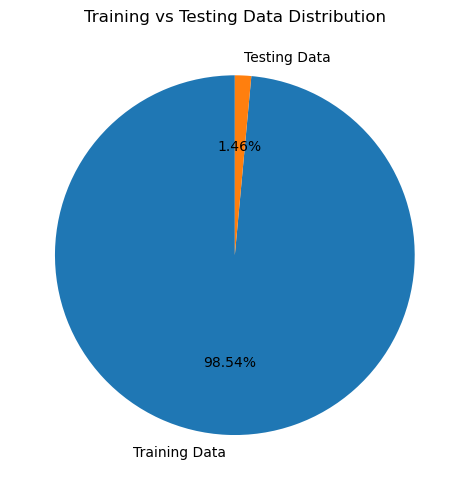

In [106]:
import matplotlib.pyplot as plt

labels = ["Training Data", "Testing Data"]
sizes = [train_percentage, test_percentage]

plt.figure(figsize=(7, 5))
plt.pie(
    sizes,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90
)
plt.title("Training vs Testing Data Distribution")
plt.tight_layout()
plt.show()

## Building our first Forecasting Baseline

##### NAIVE BASELINE :-If last Tuesday sold 40 units, predict 40 for this Tuesday. It needs no training, no parameters, and no math, yet it is surprisingly hard to beat on retail data with strong weekday patterns.

In [107]:
# Seasonal naive baseline: use sales from 7 days earlier
#Predict that today’s sales will equal the sales from exactly 7 days ago.
df = df.sort_values(["id", "date"]).copy()

df["naive_prediction"] = (
    df.groupby("id")["sales"].shift(7)
)

# Extract predictions for the test period
test_df = df[df["date"] >= cutoff_date].copy()

print("Test shape:", test_df.shape)
test_df[["id", "date", "sales", "naive_prediction"]].head(10)

Test shape: (28000, 27)


,id,date,sales,naive_prediction
1885000,FOODS_1_003_TX_3_validation,2016-03-28,0,0.0
1886000,FOODS_1_003_TX_3_validation,2016-03-29,0,0.0
1887000,FOODS_1_003_TX_3_validation,2016-03-30,0,1.0
1888000,FOODS_1_003_TX_3_validation,2016-03-31,0,0.0
1889000,FOODS_1_003_TX_3_validation,2016-04-01,0,0.0
1890000,FOODS_1_003_TX_3_validation,2016-04-02,0,0.0
1891000,FOODS_1_003_TX_3_validation,2016-04-03,0,2.0
1892000,FOODS_1_003_TX_3_validation,2016-04-04,0,0.0
1893000,FOODS_1_003_TX_3_validation,2016-04-05,0,0.0
1894000,FOODS_1_003_TX_3_validation,2016-04-06,0,0.0


In [108]:
print("Missing predictions:", test_df["naive_prediction"].isna().sum())
print("Actual sales total:", test_df["sales"].sum())
print("Predicted sales total:", test_df["naive_prediction"].sum())

Missing predictions: 0
Actual sales total: 33720
Predicted sales total: 33738.0


##### The difference is 33,738 − 33,720 = 18 units, which is about 0.05% of actual sales. In other words, the baseline’s overall bias is almost zero: it neither over- nor under-forecasts in total.

### Calculate WAPE 

##### WAPE means Weighted Absolute Percentage Error. Lower is better.

##### WAPE=∑|Actual−Predicted|​×100/ ∑|actual|

In [109]:
from sklearn.metrics import mean_absolute_error
import numpy as np

actual = test_df["sales"].to_numpy()
predicted = test_df["naive_prediction"].to_numpy()

wape = (
    np.abs(actual - predicted).sum()
    / np.abs(actual).sum()
) * 100

mae = mean_absolute_error(actual, predicted)

print(f"Seasonal Naive WAPE: {wape:.2f}%")
print(f"Seasonal Naive MAE:  {mae:.4f}")

Seasonal Naive WAPE: 90.96%
Seasonal Naive MAE:  1.0954


##### The sum of absolute prediction errors is 90.96% of total actual sales. This gives us a baseline to compare against our next models.

### Visualize actual vs predicted demand

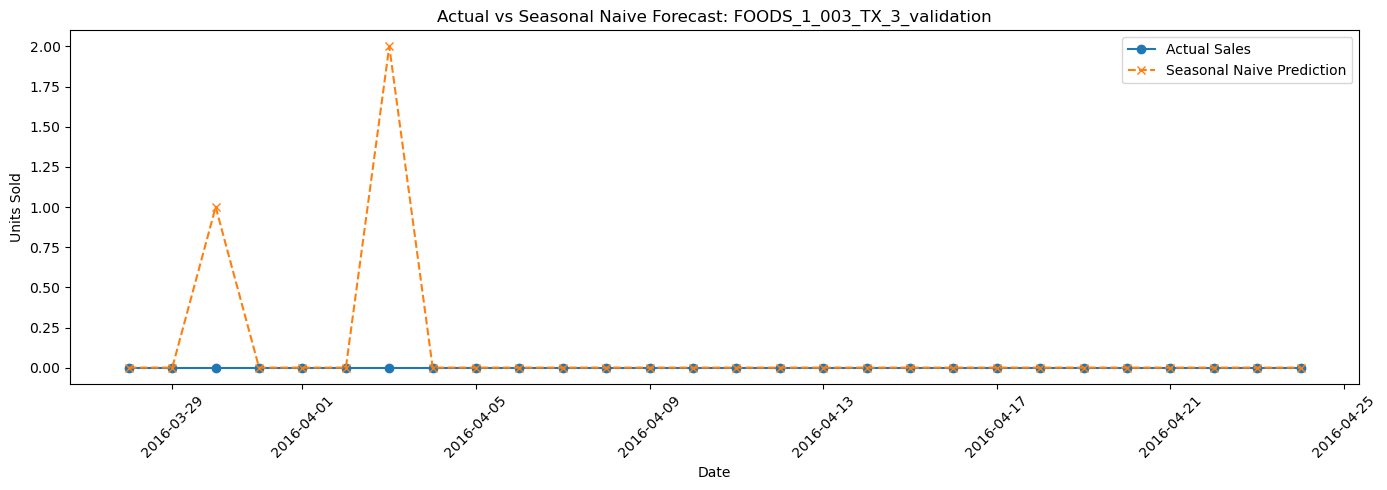

In [110]:
import matplotlib.pyplot as plt

example_id = test_df["id"].iloc[0]

plot_df = test_df[test_df["id"] == example_id].sort_values("date")

plt.figure(figsize=(14, 5))

plt.plot(
    plot_df["date"],
    plot_df["sales"],
    label="Actual Sales",
    marker="o"
)

plt.plot(
    plot_df["date"],
    plot_df["naive_prediction"],
    label="Seasonal Naive Prediction",
    linestyle="--",
    marker="x"
)

plt.title(f"Actual vs Seasonal Naive Forecast: {example_id}")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("Actual _vs_naive_forecast.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
for pid in test_df["id"].unique()[:3]:
    p = test_df[test_df["id"] == pid].sort_values("date")
    plt.figure(figsize=(10, 7))
    plt.plot(p["date"], p["sales"], marker="o", label="Actual")
    plt.plot(p["date"], p["naive_prediction"], "--x", label="Naive")
    plt.title(f"Actual vs Naive: {pid}")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig("multiple_Actual _vs_naive_forecast.png", dpi=300, bbox_inches="tight")
    plt.show()

### Save the baseline result

In [112]:
baseline_results = pd.DataFrame({
    "Model": ["Seasonal Naive"],
    "WAPE (%)": [wape],
    "MAE": [mae]
})

baseline_results

,Model,WAPE (%),MAE
0,Seasonal Naive,90.960854,1.095429


In [113]:
from pathlib import Path

output_dir = Path("../reports")
output_dir.mkdir(parents=True, exist_ok=True)

baseline_results.to_csv(
    output_dir / "baseline_results.csv",
    index=False
)

print("Baseline results saved successfully.")

Baseline results saved successfully.


## LINEAR REGRESSION 

### importing lib

In [114]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

In [115]:
features = [
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "day_of_week",
    "month",
    "is_event",
    "snap_CA",
    "snap_TX",
    "snap_WI"
]

target = "sales"

In [116]:
model_df = df.dropna(subset=features + [target]).copy()

print("Original shape:", df.shape)
print("Model-ready shape:", model_df.shape)
print("Missing feature values:", model_df[features].isnull().sum().sum())

Original shape: (1913000, 27)
Model-ready shape: (1885000, 27)
Missing feature values: 0


In [117]:
train_model = model_df[model_df["date"] < cutoff_date].copy()
test_model = model_df[model_df["date"] >= cutoff_date].copy()

X_train = train_model[features]
y_train = train_model[target]

X_test = test_model[features]
y_test = test_model[target]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1857000, 11)
X_test: (28000, 11)
y_train: (1857000,)
y_test: (28000,)


In [118]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_predictions = np.clip(lr_model.predict(X_test), 0, None)

lr_wape = (
    np.abs(y_test.to_numpy() - lr_predictions).sum()
    / np.abs(y_test.to_numpy()).sum()
) * 100

lr_mae = mean_absolute_error(y_test, lr_predictions)

print(f"Linear Regression WAPE: {lr_wape:.2f}%")
print(f"Linear Regression MAE: {lr_mae:.4f}")

Linear Regression WAPE: 76.62%
Linear Regression MAE: 0.9227


In [119]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = np.clip(rf_model.predict(X_test), 0, None)

rf_wape = (
    np.abs(y_test.to_numpy() - rf_predictions).sum()
    / np.abs(y_test.to_numpy()).sum()
) * 100

rf_mae = mean_absolute_error(y_test, rf_predictions)

print(f"Random Forest WAPE: {rf_wape:.2f}%")
print(f"Random Forest MAE: {rf_mae:.4f}")

Random Forest WAPE: 74.55%
Random Forest MAE: 0.8977


In [120]:
model_results = pd.DataFrame([
    {
        "Model": "Seasonal Naive",
        "WAPE (%)": wape,
        "MAE": mae
    },
    {
        "Model": "Linear Regression",
        "WAPE (%)": lr_wape,
        "MAE": lr_mae
    },
    {
        "Model": "Random Forest",
        "WAPE (%)": rf_wape,
        "MAE": rf_mae
    }
])

model_results = model_results.sort_values("WAPE (%)")

model_results

,Model,WAPE (%),MAE
2,Random Forest,74.546188,0.897749
1,Linear Regression,76.616190,0.922678
0,Seasonal Naive,90.960854,1.095429


In [121]:
model_results.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


# LIGHTGBM

In [122]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [123]:
import lightgbm as lgb
import numpy as np
from sklearn.metrics import mean_absolute_error

lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(X_train, y_train)

lgb_predictions = np.clip(
    lgb_model.predict(X_test),
    0,
    None
)

lgb_wape = (
    np.abs(y_test.to_numpy() - lgb_predictions).sum()
    / np.abs(y_test.to_numpy()).sum()
) * 100

lgb_mae = mean_absolute_error(y_test, lgb_predictions)

print(f"LightGBM WAPE: {lgb_wape:.2f}%")
print(f"LightGBM MAE: {lgb_mae:.4f}")

LightGBM WAPE: 74.76%
LightGBM MAE: 0.9003


In [124]:
model_results = pd.DataFrame([
    {"Model": "Seasonal Naive", "WAPE (%)": wape, "MAE": mae},
    {"Model": "Linear Regression", "WAPE (%)": lr_wape, "MAE": lr_mae},
    {"Model": "Random Forest", "WAPE (%)": rf_wape, "MAE": rf_mae},
    {"Model": "LightGBM", "WAPE (%)": lgb_wape, "MAE": lgb_mae}
])

model_results = model_results.sort_values("WAPE (%)").reset_index(drop=True)

model_results

,Model,WAPE (%),MAE
0,Random Forest,74.546188,0.897749
1,LightGBM,74.755753,0.900273
2,Linear Regression,76.616190,0.922678
3,Seasonal Naive,90.960854,1.095429


In [125]:
model_results.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("Updated model comparison saved!")

Updated model comparison saved!


In [126]:
import numpy as np

def calculate_rmsse(train_actual, test_actual, test_predicted):
    """
    Calculate RMSSE using a one-step naive scaling denominator.
    """

    numerator = np.mean(
        (np.asarray(test_actual) - np.asarray(test_predicted)) ** 2
    )

    denominator = np.mean(
        np.diff(np.asarray(train_actual)) ** 2
    )

    if denominator == 0:
        return np.nan

    return np.sqrt(numerator / denominator)

In [127]:
def calculate_mean_series_rmsse(train_df, test_df, prediction_column):
    train_groups = {
        product_id: group.sort_values("date")["sales"].to_numpy()
        for product_id, group in train_df.groupby("id")
    }

    scores = []

    for product_id, group in test_df.groupby("id"):
        train_sales = train_groups.get(product_id)

        if train_sales is None or len(train_sales) < 2:
            continue

        group = group.sort_values("date")
        actual = group["sales"].to_numpy()
        predicted = group[prediction_column].to_numpy()

        denominator = np.mean(np.diff(train_sales) ** 2)

        if denominator == 0:
            continue

        score = np.sqrt(np.mean((actual - predicted) ** 2) / denominator)
        scores.append(score)

    return np.mean(scores) if scores else np.nan

In [128]:
score = calculate_mean_series_rmsse(
    train_df,
    test_df,
    "naive_prediction"
)

print(f"Seasonal Naive RMSSE: {score:.4f}")

Seasonal Naive RMSSE: 1.1786


### Compare Model performance

In [134]:
# Check which prediction variables exist in memory

prediction_variables = [
    "lr_predictions",
    "lr_price_predictions",
    "rf_predictions",
    "rf_price_predictions",
    "lgb_predictions",
    "lgb_price_predictions"
]

for name in prediction_variables:
    if name in globals():
        value = globals()[name]
        print(f"{name}: EXISTS | Length: {len(value)}")
    else:
        print(f"{name}: NOT FOUND")

lr_predictions: EXISTS | Length: 28000
lr_price_predictions: EXISTS | Length: 383000
rf_predictions: EXISTS | Length: 28000
rf_price_predictions: EXISTS | Length: 383000
lgb_predictions: EXISTS | Length: 28000
lgb_price_predictions: EXISTS | Length: 383000


In [136]:
print("test_df shape:", test_df.shape)
print("test_model shape:", test_model.shape)

print("\nBaseline prediction lengths:")
print("Linear Regression:", len(lr_predictions))
print("Random Forest:", len(rf_predictions))
print("LightGBM:", len(lgb_predictions))

print("\nAvailable prediction columns in test_df:")
print([
    col for col in test_df.columns
    if "prediction" in col.lower()
])

test_df shape: (28000, 27)
test_model shape: (28000, 27)

Baseline prediction lengths:
Linear Regression: 28000
Random Forest: 28000
LightGBM: 28000

Available prediction columns in test_df:
['naive_prediction']


In [137]:
# Attach existing baseline predictions to their matching test rows

test_model = test_model.copy()

test_model["lr_prediction"] = lr_predictions
test_model["rf_prediction"] = rf_predictions
test_model["lgb_prediction"] = lgb_predictions

print("Prediction columns added successfully.")
print(
    test_model[
        ["sales", "lr_prediction", "rf_prediction", "lgb_prediction"]
    ].head()
)

print("\nShape:", test_model.shape)

Prediction columns added successfully.
         sales  lr_prediction  rf_prediction  lgb_prediction
1885000      0       0.494534       0.643631        0.354815
1886000      0       0.130311       0.235335        0.223641
1887000      0       0.195017       0.226934        0.209817
1888000      0       0.164957       0.180341        0.206471
1889000      0       0.268651       0.182745        0.262942

Shape: (28000, 30)


In [138]:
rmsse_results = {
    "Seasonal Naive": calculate_mean_series_rmsse(
        train_df, test_df, "naive_prediction"
    ),
    "Linear Regression": calculate_mean_series_rmsse(
        train_df, test_model, "lr_prediction"
    ),
    "Random Forest": calculate_mean_series_rmsse(
        train_df, test_model, "rf_prediction"
    ),
    "LightGBM": calculate_mean_series_rmsse(
        train_df, test_model, "lgb_prediction"
    )
}

print("Baseline RMSSE Results:")
for model, score in rmsse_results.items():
    print(f"{model}: {score:.4f}")

Baseline RMSSE Results:
Seasonal Naive: 1.1786
Linear Regression: 0.9048
Random Forest: 0.8688
LightGBM: 0.8727


In [139]:
model_results = pd.DataFrame([
    {
        "Model": "Seasonal Naive",
        "WAPE (%)": wape,
        "MAE": mae,
        "RMSSE": rmsse_results.get("Seasonal Naive", np.nan)
    },
    {
        "Model": "Linear Regression",
        "WAPE (%)": lr_wape,
        "MAE": lr_mae,
        "RMSSE": rmsse_results.get("Linear Regression", np.nan)
    },
    {
        "Model": "Random Forest",
        "WAPE (%)": rf_wape,
        "MAE": rf_mae,
        "RMSSE": rmsse_results.get("Random Forest", np.nan)
    },
    {
        "Model": "LightGBM",
        "WAPE (%)": lgb_wape,
        "MAE": lgb_mae,
        "RMSSE": rmsse_results.get("LightGBM", np.nan)
    }
])

model_results = model_results.sort_values("WAPE (%)").reset_index(drop=True)

display(model_results)

,Model,WAPE (%),MAE,RMSSE
0,Random Forest,74.546188,0.897749,0.868765
1,LightGBM,74.755753,0.900273,0.872687
2,Linear Regression,76.616190,0.922678,0.904799
3,Seasonal Naive,90.960854,1.095429,1.178628


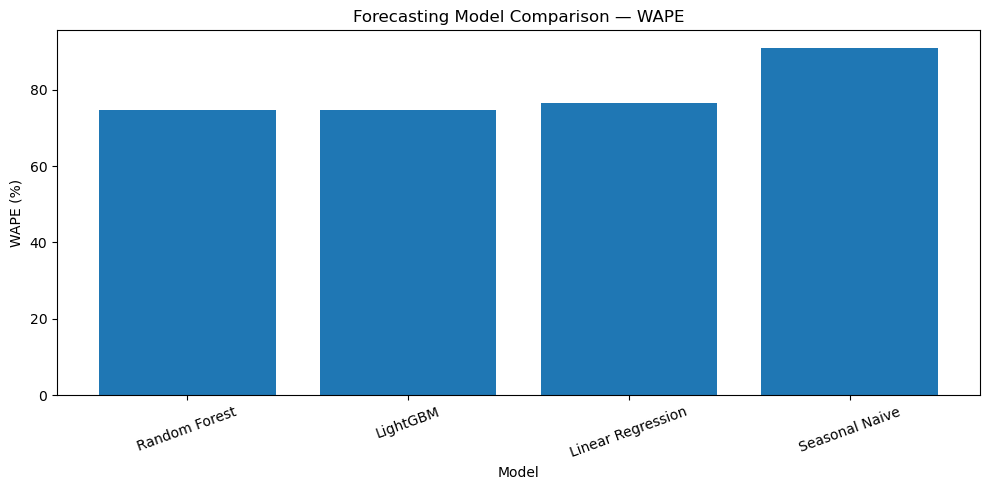

In [140]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(model_results["Model"], model_results["WAPE (%)"])

plt.title("Forecasting Model Comparison — WAPE")
plt.xlabel("Model")
plt.ylabel("WAPE (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

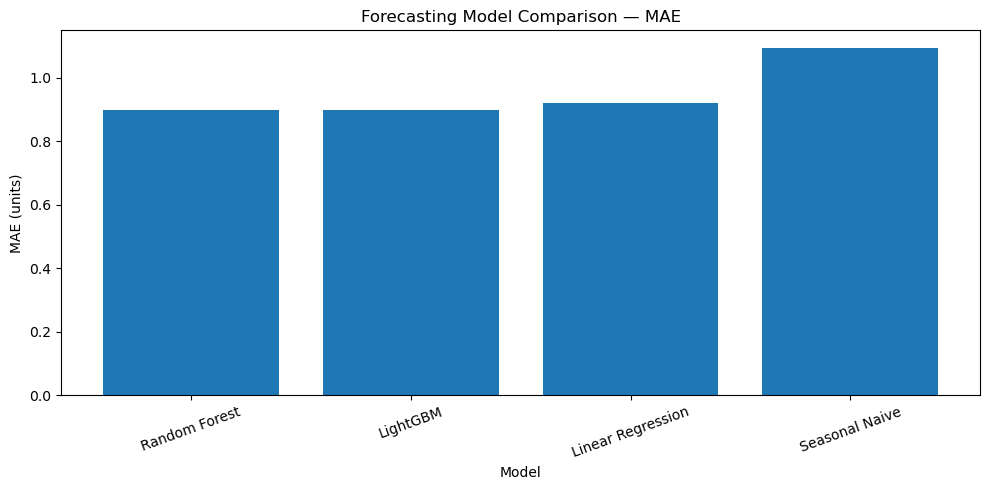

In [141]:
plt.figure(figsize=(10, 5))

plt.bar(model_results["Model"], model_results["MAE"])

plt.title("Forecasting Model Comparison — MAE")
plt.xlabel("Model")
plt.ylabel("MAE (units)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [142]:
from pathlib import Path

output_dir = Path("../reports")
output_dir.mkdir(parents=True, exist_ok=True)

model_results.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [143]:
model_results.sort_values("WAPE (%)")

,Model,WAPE (%),MAE,RMSSE
0,Random Forest,74.546188,0.897749,0.868765
1,LightGBM,74.755753,0.900273,0.872687
2,Linear Regression,76.616190,0.922678,0.904799
3,Seasonal Naive,90.960854,1.095429,1.178628


### Add selling-price feautures

In [144]:
from pathlib import Path
import pandas as pd

# Load price and calendar data
prices = pd.read_csv("../data/raw/m5-forecasting-accuracy/sell_prices.csv")
calendar = pd.read_csv("../data/raw/m5-forecasting-accuracy/calendar.csv")

print("Prices shape:", prices.shape)
print("Calendar shape:", calendar.shape)

print("\nPrice columns:")
print(prices.columns.tolist())

print("\nCalendar columns:")
print(calendar[["d", "date", "wm_yr_wk"]].head())

Prices shape: (6841121, 4)
Calendar shape: (1969, 14)

Price columns:
['store_id', 'item_id', 'wm_yr_wk', 'sell_price']

Calendar columns:
     d        date  wm_yr_wk
0  d_1  2011-01-29     11101
1  d_2  2011-01-30     11101
2  d_3  2011-01-31     11101
3  d_4  2011-02-01     11101
4  d_5  2011-02-02     11101


In [145]:
# Keep only the columns needed for the merge
price_data = prices[
    ["store_id", "item_id", "wm_yr_wk", "sell_price"]
].copy()

calendar_data = calendar[["d", "wm_yr_wk"]].copy()

# Add week information to daily sales
sales_with_calendar = df.merge(
    calendar_data,
    left_on="d",
    right_on="d",
    how="left",
    validate="many_to_one"
)

# Merge selling prices
sales_with_prices = sales_with_calendar.merge(
    price_data,
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left",
    validate="many_to_one"
)

print("Original rows:", len(df))
print("Rows after merging:", len(sales_with_prices))
print("Missing selling prices:", sales_with_prices["sell_price"].isna().sum())

sales_with_prices.head()

Original rows: 1913000
Rows after merging: 1913000
Missing selling prices: 420812


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,day_number,lag_1,...,event_type_2,snap_CA,snap_TX,snap_WI,day_of_week,month,is_event,naive_prediction,wm_yr_wk,sell_price
0,FOODS_1_003_TX_3_validation,FOODS_1_003,FOODS_1,FOODS,TX_3,TX,d_1,1,1,NaN,...,None,0,0,0,5,1,0,NaN,11101,2.88
1,FOODS_1_003_TX_3_validation,FOODS_1_003,FOODS_1,FOODS,TX_3,TX,d_2,0,2,1.0,...,None,0,0,0,6,1,0,NaN,11101,2.88
2,FOODS_1_003_TX_3_validation,FOODS_1_003,FOODS_1,FOODS,TX_3,TX,d_3,0,3,0.0,...,None,0,0,0,0,1,0,NaN,11101,2.88
3,FOODS_1_003_TX_3_validation,FOODS_1_003,FOODS_1,FOODS,TX_3,TX,d_4,2,4,0.0,...,None,1,1,0,1,2,0,NaN,11101,2.88
4,FOODS_1_003_TX_3_validation,FOODS_1_003,FOODS_1,FOODS,TX_3,TX,d_5,0,5,2.0,...,None,1,0,1,2,2,0,NaN,11101,2.88


In [146]:
# Sort each product-store series chronologically
sales_with_prices = sales_with_prices.sort_values(
    ["id", "date"]
).copy()

# Previous week's selling price
sales_with_prices["previous_price"] = (
    sales_with_prices.groupby("id")["sell_price"].shift(7)
)

# Percentage change relative to previous week's price
sales_with_prices["price_change_pct"] = (
    (
        sales_with_prices["sell_price"]
        - sales_with_prices["previous_price"]
    )
    / sales_with_prices["previous_price"].replace(0, np.nan)
) * 100

# Price change indicator
sales_with_prices["price_changed"] = (
    sales_with_prices["sell_price"]
    != sales_with_prices["previous_price"]
).astype("int8")

print("Dataset shape:", sales_with_prices.shape)

print("\nMissing current prices:",
      sales_with_prices["sell_price"].isna().sum())

print("\nPrice-change summary:")
print(sales_with_prices["price_change_pct"].describe().round(2))

print("\nPrice-change examples:")
print(
    sales_with_prices[
        ["id", "date", "sell_price", "previous_price",
         "price_change_pct", "price_changed"]
    ].head(10)
)

Dataset shape: (1913000, 32)

Missing current prices: 420812

Price-change summary:
count    1485188.00
mean           0.07
std            6.83
min          -95.97
25%            0.00
50%            0.00
75%            0.00
max         2380.00
Name: price_change_pct, dtype: float64

Price-change examples:
                            id       date  sell_price  previous_price  \
0  FOODS_1_003_TX_3_validation 2011-01-29        2.88             NaN   
1  FOODS_1_003_TX_3_validation 2011-01-30        2.88             NaN   
2  FOODS_1_003_TX_3_validation 2011-01-31        2.88             NaN   
3  FOODS_1_003_TX_3_validation 2011-02-01        2.88             NaN   
4  FOODS_1_003_TX_3_validation 2011-02-02        2.88             NaN   
5  FOODS_1_003_TX_3_validation 2011-02-03        2.88             NaN   
6  FOODS_1_003_TX_3_validation 2011-02-04        2.88             NaN   
7  FOODS_1_003_TX_3_validation 2011-02-05        2.88            2.88   
8  FOODS_1_003_TX_3_validation 2011-

In [147]:
sales_with_prices["price_changed"] = (
    sales_with_prices["sell_price"]
    .ne(sales_with_prices["previous_price"])
    & sales_with_prices["previous_price"].notna()
    & sales_with_prices["sell_price"].notna()
).astype("int8")

print(sales_with_prices["price_changed"].value_counts())

price_changed
0    1896355
1      16645
Name: count, dtype: int64


In [148]:
price_columns = [
    "sell_price",
    "previous_price",
    "price_change_pct",
    "price_changed"
]

print("Missing values:")
print(sales_with_prices[price_columns].isnull().sum())

print("\nPrice change indicator:")
print(sales_with_prices["price_changed"].value_counts())

print("\nPrice change percentage summary:")
print(sales_with_prices["price_change_pct"].describe())

Missing values:
sell_price          420812
previous_price      427812
price_change_pct    427812
price_changed            0
dtype: int64

Price change indicator:
price_changed
0    1896355
1      16645
Name: count, dtype: int64

Price change percentage summary:
count    1.485188e+06
mean     6.881190e-02
std      6.826779e+00
min     -9.596774e+01
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.380000e+03
Name: price_change_pct, dtype: float64


In [149]:
print("Missing current prices by category:")
print(
    sales_with_prices.loc[
        sales_with_prices["sell_price"].isna()
    ].groupby("cat_id").size()
)

print("\nMissing current prices by state:")
print(
    sales_with_prices.loc[
        sales_with_prices["sell_price"].isna()
    ].groupby("state_id").size()
)

print("\nExamples of missing prices:")
print(
    sales_with_prices.loc[
        sales_with_prices["sell_price"].isna(),
        ["id", "item_id", "store_id", "state_id", "d", "wm_yr_wk"]
    ].head(10)
)

Missing current prices by category:
cat_id
FOODS        196763
HOBBIES       87451
HOUSEHOLD    136598
dtype: int64

Missing current prices by state:
state_id
CA    178787
TX    120001
WI    122024
dtype: int64

Examples of missing prices:
                               id      item_id store_id state_id     d  \
7652  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_1   
7653  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_2   
7654  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_3   
7655  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_4   
7656  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_5   
7657  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_6   
7658  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_7   
7659  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_8   
7660  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_9   
7661  FOODS_1_008_CA

In [150]:
model_df = sales_with_prices.copy()

price_features = [
    "sell_price",
    "price_change_pct",
    "price_changed"
]

print("Dataset shape:", model_df.shape)

print("\nPrice feature missing values:")
print(model_df[price_features].isnull().sum())

print("\nAvailable columns:")
print(model_df.columns.tolist())

Dataset shape: (1913000, 32)

Price feature missing values:
sell_price          420812
price_change_pct    427812
price_changed            0
dtype: int64

Available columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'day_number', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'date', 'weekday', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'day_of_week', 'month', 'is_event', 'naive_prediction', 'wm_yr_wk', 'sell_price', 'previous_price', 'price_change_pct', 'price_changed']


In [151]:
# Check whether missing prices are concentrated in specific categories
missing_price_summary = (
    model_df.assign(
        price_missing=model_df["sell_price"].isna()
    )
    .groupby("cat_id")
    .agg(
        total_rows=("sell_price", "size"),
        missing_prices=("price_missing", "sum")
    )
)

missing_price_summary["missing_percentage"] = (
    missing_price_summary["missing_prices"]
    / missing_price_summary["total_rows"]
    * 100
)

print(missing_price_summary)

           total_rows  missing_prices  missing_percentage
cat_id                                                   
FOODS          906762          196763           21.699520
HOBBIES        384513           87451           22.743314
HOUSEHOLD      621725          136598           21.970807


In [152]:
missing_by_week = (
    model_df[model_df["sell_price"].isna()]
    .groupby("wm_yr_wk")
    .size()
    .sort_values(ascending=False)
)

print("Weeks with the most missing prices:")
print(missing_by_week.head(10))

print("\nTotal unique weeks:", model_df["wm_yr_wk"].nunique())

print("\nMissing prices by state:")
print(
    model_df[model_df["sell_price"].isna()]
    .groupby("state_id")
    .size()
)

Weeks with the most missing prices:
wm_yr_wk
11101    4550
11102    4326
11103    4200
11104    4095
11105    4004
11106    3941
11107    3871
11108    3850
11109    3794
11110    3745
dtype: int64

Total unique weeks: 274

Missing prices by state:
state_id
CA    178787
TX    120001
WI    122024
dtype: int64


In [153]:
# Check whether missing-price rows have a matching item-store pair
price_pairs = prices[["store_id", "item_id"]].drop_duplicates()

price_check = model_df.loc[
    model_df["sell_price"].isna(),
    ["store_id", "item_id", "wm_yr_wk"]
].merge(
    price_pairs.assign(pair_exists=True),
    on=["store_id", "item_id"],
    how="left"
)

print("Missing-price rows:", len(price_check))

print("\nItem-store pairs that exist in the price dataset:")
print(price_check["pair_exists"].eq(True).sum())

print("\nItem-store pairs absent from the price dataset:")
print(price_check["pair_exists"].isna().sum())

Missing-price rows: 420812

Item-store pairs that exist in the price dataset:
420812

Item-store pairs absent from the price dataset:
0


In [154]:
# Select one item-store pair with a missing price
missing_example = model_df.loc[
    model_df["sell_price"].isna(),
    ["item_id", "store_id", "wm_yr_wk"]
].iloc[0]

item = missing_example["item_id"]
store = missing_example["store_id"]
week = missing_example["wm_yr_wk"]

print("Item:", item)
print("Store:", store)
print("Week with missing price:", week)

print("\nAvailable prices for this item-store pair:")
print(
    prices.loc[
        (prices["item_id"] == item)
        & (prices["store_id"] == store)
    ].sort_values("wm_yr_wk").head(15)
)

Item: FOODS_1_008
Store: CA_2
Week with missing price: 11101

Available prices for this item-store pair:
        store_id      item_id  wm_yr_wk  sell_price
1066742     CA_2  FOODS_1_008     11201        3.28
1066743     CA_2  FOODS_1_008     11202        3.28
1066744     CA_2  FOODS_1_008     11203        3.28
1066745     CA_2  FOODS_1_008     11204        3.28
1066746     CA_2  FOODS_1_008     11205        3.28
1066747     CA_2  FOODS_1_008     11206        3.28
1066748     CA_2  FOODS_1_008     11207        3.28
1066749     CA_2  FOODS_1_008     11208        3.28
1066750     CA_2  FOODS_1_008     11209        3.28
1066751     CA_2  FOODS_1_008     11210        3.28
1066752     CA_2  FOODS_1_008     11211        3.28
1066753     CA_2  FOODS_1_008     11212        3.28
1066754     CA_2  FOODS_1_008     11213        3.28
1066755     CA_2  FOODS_1_008     11214        3.28
1066756     CA_2  FOODS_1_008     11215        3.28


In [155]:
item_prices = prices[
    (prices["item_id"] == item)
    & (prices["store_id"] == store)
].sort_values("wm_yr_wk")

print("First available price week:", item_prices["wm_yr_wk"].min())
print("Last available price week:", item_prices["wm_yr_wk"].max())

print("\nPrice history:")
print(item_prices[["wm_yr_wk", "sell_price"]].head(5))

print("\nNumber of weeks with recorded prices:", len(item_prices))

First available price week: 11201
Last available price week: 11621

Price history:
         wm_yr_wk  sell_price
1066742     11201        3.28
1066743     11202        3.28
1066744     11203        3.28
1066745     11204        3.28
1066746     11205        3.28

Number of weeks with recorded prices: 230


In [156]:
price_coverage = (
    sales_with_prices
    .groupby("state_id")
    .agg(
        total_rows=("sales", "size"),
        available_prices=("sell_price", "count")
    )
)

price_coverage["price_coverage_pct"] = (
    price_coverage["available_prices"]
    / price_coverage["total_rows"]
    * 100
).round(2)

print(price_coverage)

print(
    "\nOverall price coverage:",
    round(sales_with_prices["sell_price"].notna().mean() * 100, 2),
    "%"
)

          total_rows  available_prices  price_coverage_pct
state_id                                                  
CA            778591            599804               77.04
TX            583465            463464               79.43
WI            550944            428920               77.85

Overall price coverage: 78.0 %


In [157]:
model_df = sales_with_prices.sort_values(
    ["date", "id"]
).copy()

unique_dates = sorted(model_df["date"].unique())

split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

train_df = model_df[model_df["date"] < split_date].copy()
test_df = model_df[model_df["date"] >= split_date].copy()

print("Split date:", split_date)
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nTraining date range:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting date range:")
print(test_df["date"].min(), "to", test_df["date"].max())

Split date: 2015-04-08 00:00:00
Training rows: 1530000
Testing rows: 383000

Training date range:
2011-01-29 00:00:00 to 2015-04-07 00:00:00

Testing date range:
2015-04-08 00:00:00 to 2016-04-24 00:00:00


In [158]:
# Create a separate copy for the price-feature experiment
price_model_df = sales_with_prices.copy()

# Add an indicator for missing prices
price_model_df["price_missing"] = (
    price_model_df["sell_price"].isna()
).astype("int8")

# Check the new features
print("Dataset shape:", price_model_df.shape)

print("\nMissing-price indicator:")
print(price_model_df["price_missing"].value_counts())

print("\nPrice feature summary:")
print(
    price_model_df[
        ["sell_price", "price_change_pct", "price_changed", "price_missing"]
    ].describe()
)

Dataset shape: (1913000, 33)

Missing-price indicator:
price_missing
0    1492188
1     420812
Name: count, dtype: int64

Price feature summary:
         sell_price  price_change_pct  price_changed  price_missing
count  1.492188e+06      1.485188e+06   1.913000e+06   1.913000e+06
mean   4.443153e+00      6.881190e-02   8.700993e-03   2.199749e-01
std    3.616720e+00      6.826779e+00   9.287244e-02   4.142295e-01
min    5.000000e-02     -9.596774e+01   0.000000e+00   0.000000e+00
25%    2.120000e+00      0.000000e+00   0.000000e+00   0.000000e+00
50%    3.370000e+00      0.000000e+00   0.000000e+00   0.000000e+00
75%    5.860000e+00      0.000000e+00   0.000000e+00   0.000000e+00
max    3.098000e+01      2.380000e+03   1.000000e+00   1.000000e+00


In [159]:
# Create chronological training and testing sets
price_model_df = price_model_df.sort_values(
    ["date", "id"]
).copy()

unique_dates = sorted(price_model_df["date"].unique())
split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

train_df = price_model_df[
    price_model_df["date"] < split_date
].copy()

test_df = price_model_df[
    price_model_df["date"] >= split_date
].copy()

# Calculate fallback median using training data only
global_price_median = train_df["sell_price"].median()

# Calculate each item's median using training data only
item_store_medians = train_df.groupby("id")["sell_price"].median()

# Fill missing prices using training-derived medians
for dataset in [train_df, test_df]:
    dataset["sell_price_imputed"] = (
        dataset["sell_price"]
        .fillna(dataset["id"].map(item_store_medians))
        .fillna(global_price_median)
    )

print("Split date:", split_date)
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nRemaining missing prices:")
print("Train:", train_df["sell_price_imputed"].isna().sum())
print("Test:", test_df["sell_price_imputed"].isna().sum())

print("\nTraining median price:", global_price_median)

Split date: 2015-04-08 00:00:00
Training rows: 1530000
Testing rows: 383000

Remaining missing prices:
Train: 0
Test: 0

Training median price: 3.34


In [160]:
# Inspect the largest absolute price changes
extreme_price_changes = (
    price_model_df.loc[
        price_model_df["price_change_pct"].notna(),
        [
            "id",
            "date",
            "sell_price",
            "previous_price",
            "price_change_pct"
        ]
    ]
    .assign(
        absolute_change=lambda x: x["price_change_pct"].abs()
    )
    .sort_values("absolute_change", ascending=False)
)

print(extreme_price_changes.head(15).to_string(index=False))

                             id       date  sell_price  previous_price  price_change_pct  absolute_change
    FOODS_3_425_TX_3_validation 2013-06-21        2.48            0.10       2380.000000      2380.000000
    FOODS_3_425_TX_3_validation 2013-06-17        2.48            0.10       2380.000000      2380.000000
    FOODS_3_425_TX_3_validation 2013-06-19        2.48            0.10       2380.000000      2380.000000
    FOODS_3_425_TX_3_validation 2013-06-15        2.48            0.10       2380.000000      2380.000000
    FOODS_3_425_TX_3_validation 2013-06-16        2.48            0.10       2380.000000      2380.000000
    FOODS_3_425_TX_3_validation 2013-06-20        2.48            0.10       2380.000000      2380.000000
    FOODS_3_425_TX_3_validation 2013-06-18        2.48            0.10       2380.000000      2380.000000
    FOODS_2_231_TX_3_validation 2014-08-27        2.75            0.20       1275.000000      1275.000000
    FOODS_2_231_TX_3_validation 2014-08-25    

In [161]:
import numpy as np

# Calculate log price change only when both prices are positive
valid_prices = (
    sales_with_prices["sell_price"].gt(0)
    & sales_with_prices["previous_price"].gt(0)
)

sales_with_prices["log_price_change"] = np.nan

sales_with_prices.loc[valid_prices, "log_price_change"] = np.log(
    sales_with_prices.loc[valid_prices, "sell_price"]
    / sales_with_prices.loc[valid_prices, "previous_price"]
)

print("Log price change summary:")
print(sales_with_prices["log_price_change"].describe())

print("\nLargest absolute log price changes:")
print(
    sales_with_prices.loc[
        sales_with_prices["log_price_change"].notna(),
        ["id", "date", "sell_price", "previous_price", "log_price_change"]
    ]
    .assign(
        abs_log_change=lambda x: x["log_price_change"].abs()
    )
    .sort_values("abs_log_change", ascending=False)
    .head(10)
    .to_string(index=False)
)

Log price change summary:
count    1.485188e+06
mean     9.053984e-05
std      3.135512e-02
min     -3.210844e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.210844e+00
Name: log_price_change, dtype: float64

Largest absolute log price changes:
                         id       date  sell_price  previous_price  log_price_change  abs_log_change
FOODS_3_425_TX_3_validation 2013-06-10        0.10            2.48         -3.210844        3.210844
FOODS_3_425_TX_3_validation 2013-06-09        0.10            2.48         -3.210844        3.210844
FOODS_3_425_TX_3_validation 2013-06-13        0.10            2.48         -3.210844        3.210844
FOODS_3_425_TX_3_validation 2013-06-14        0.10            2.48         -3.210844        3.210844
FOODS_3_425_TX_3_validation 2013-06-15        2.48            0.10          3.210844        3.210844
FOODS_3_425_TX_3_validation 2013-06-16        2.48            0.10          3.210844        3.210844
FOODS_3_425_TX_

In [162]:
price_model_df = sales_with_prices.copy()

price_model_df["price_missing"] = (
    price_model_df["sell_price"].isna()
).astype("int8")

price_features = [
    "sell_price",
    "log_price_change",
    "price_changed",
    "price_missing"
]

print("Price features:", price_features)

print("\nMissing values:")
print(price_model_df[price_features].isna().sum())

print("\nDataset shape:", price_model_df.shape)

Price features: ['sell_price', 'log_price_change', 'price_changed', 'price_missing']

Missing values:
sell_price          420812
log_price_change    427812
price_changed            0
price_missing            0
dtype: int64

Dataset shape: (1913000, 34)


### Impute Price Features Without Leakage

In [163]:
# Create the chronological split
price_model_df = price_model_df.sort_values(
    ["date", "id"]
).copy()

unique_dates = sorted(price_model_df["date"].unique())
split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

train_df = price_model_df[
    price_model_df["date"] < split_date
].copy()

test_df = price_model_df[
    price_model_df["date"] >= split_date
].copy()

# Calculate imputation values using training data only
global_price_median = train_df["sell_price"].median()
global_log_change_median = train_df["log_price_change"].median()

item_price_medians = train_df.groupby("id")["sell_price"].median()

# Impute prices using each series' training median, then global fallback
for dataset in [train_df, test_df]:
    dataset["sell_price_imputed"] = (
        dataset["sell_price"]
        .fillna(dataset["id"].map(item_price_medians))
        .fillna(global_price_median)
    )

    dataset["log_price_change_imputed"] = (
        dataset["log_price_change"]
        .fillna(global_log_change_median)
    )

print("Split date:", split_date)

print("\nRemaining missing values:")
print(
    train_df[
        ["sell_price_imputed", "log_price_change_imputed"]
    ].isna().sum()
)

print(
    test_df[
        ["sell_price_imputed", "log_price_change_imputed"]
    ].isna().sum()
)

Split date: 2015-04-08 00:00:00

Remaining missing values:
sell_price_imputed          0
log_price_change_imputed    0
dtype: int64
sell_price_imputed          0
log_price_change_imputed    0
dtype: int64


### Prepare the Model Features

In [164]:
base_features = [
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "day_of_week",
    "month",
    "is_event",
    "snap_CA",
    "snap_TX",
    "snap_WI"
]

price_features = [
    "sell_price_imputed",
    "log_price_change_imputed",
    "price_changed",
    "price_missing"
]

target = "sales"

# Keep rows with complete baseline features and valid targets
train_model = train_df.dropna(
    subset=base_features + [target]
).copy()

test_model = test_df.dropna(
    subset=base_features + [target]
).copy()

print("Training rows:", len(train_model))
print("Testing rows:", len(test_model))

print("\nBaseline feature count:", len(base_features))
print("Price feature count:", len(price_features))

print("\nMissing baseline features in training:")
print(train_model[base_features].isna().sum().sum())

print("\nMissing baseline features in testing:")
print(test_model[base_features].isna().sum().sum())

Training rows: 1502000
Testing rows: 383000

Baseline feature count: 11
Price feature count: 4

Missing baseline features in training:
0

Missing baseline features in testing:
0


## Training Random forest with price features

In [165]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np

# Features
X_train_price = train_model[base_features + price_features]
y_train = train_model[target]

X_test_price = test_model[base_features + price_features]
y_test = test_model[target]

# Train Random Forest
rf_price = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest with price features...")

rf_price.fit(X_train_price, y_train)

print("Training completed!")

# Predictions
rf_price_predictions = np.maximum(
    rf_price.predict(X_test_price), 0
)

# Metrics
rf_price_mae = mean_absolute_error(
    y_test, rf_price_predictions
)

rf_price_wape = (
    np.abs(y_test - rf_price_predictions).sum()
    / np.abs(y_test).sum()
) * 100

print("\nRandom Forest with Price Features")
print("MAE:", round(rf_price_mae, 4))
print("WAPE:", round(rf_price_wape, 2), "%")

Training Random Forest with price features...
Training completed!

Random Forest with Price Features
MAE: 0.8845
WAPE: 76.19 %


### TRAINING LIGHTGBM 

In [166]:
import lightgbm as lgb
import numpy as np
from sklearn.metrics import mean_absolute_error

lgb_price = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print("Training LightGBM with price features...")

lgb_price.fit(X_train_price, y_train)

print("Training completed!")

lgb_price_predictions = np.maximum(
    lgb_price.predict(X_test_price), 0
)

lgb_price_mae = mean_absolute_error(
    y_test, lgb_price_predictions
)

lgb_price_wape = (
    np.abs(y_test - lgb_price_predictions).sum()
    / np.abs(y_test).sum()
) * 100

print("\nLightGBM with Price Features")
print("MAE:", round(lgb_price_mae, 4))
print("WAPE:", round(lgb_price_wape, 2), "%")

Training LightGBM with price features...
Training completed!

LightGBM with Price Features
MAE: 0.8851
WAPE: 76.25 %


### TRAINING WITH LINEAR REGRESSION 

In [167]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import numpy as np

lr_price = LinearRegression()

print("Training Linear Regression with price features...")

lr_price.fit(X_train_price, y_train)

print("Training completed!")

lr_price_predictions = np.maximum(
    lr_price.predict(X_test_price), 0
)

lr_price_mae = mean_absolute_error(
    y_test, lr_price_predictions
)

lr_price_wape = (
    np.abs(y_test - lr_price_predictions).sum()
    / np.abs(y_test).sum()
) * 100

print("\nLinear Regression with Price Features")
print("MAE:", round(lr_price_mae, 4))
print("WAPE:", round(lr_price_wape, 2), "%")

Training Linear Regression with price features...
Training completed!

Linear Regression with Price Features
MAE: 0.9078
WAPE: 78.19 %


## Analyze Prize Impact 

### analyze price changes and sales

In [168]:
# Analyze sales when prices change vs. when they remain stable

price_impact = (
    sales_with_prices
    .groupby("price_changed")
    .agg(
        total_days=("sales", "count"),
        average_sales=("sales", "mean"),
        median_sales=("sales", "median"),
        total_sales=("sales", "sum")
    )
    .reset_index()
)

price_impact["price_status"] = price_impact["price_changed"].map({
    0: "No price change / insufficient price history",
    1: "Price changed"
})

price_impact

,price_changed,total_days,average_sales,median_sales,total_sales,price_status
0,0,1896355,0.986853,0.0,1871424,No price change / insufficient price history
1,1,16645,1.636407,0.0,27238,Price changed


In [169]:
for status, group in sales_with_prices.groupby("price_changed"):
    label = "Price changed" if status == 1 else "No detected price change"

    print(f"\n{label}")
    print(f"Number of rows: {len(group):,}")
    print(f"Average sales: {group['sales'].mean():.4f}")
    print(f"Median sales: {group['sales'].median():.4f}")
    print(f"Total sales: {group['sales'].sum():,.0f}")


No detected price change
Number of rows: 1,896,355
Average sales: 0.9869
Median sales: 0.0000
Total sales: 1,871,424

Price changed
Number of rows: 16,645
Average sales: 1.6364
Median sales: 0.0000
Total sales: 27,238


In [170]:
# Calculate the change in sales for each item-store series
sales_with_prices = sales_with_prices.sort_values(
    ["id", "date"]
).copy()

sales_with_prices["previous_sales"] = (
    sales_with_prices.groupby("id")["sales"].shift(1)
)

# Keep only rows with a detected price change and valid previous sales
price_change_analysis = sales_with_prices[
    (sales_with_prices["price_changed"] == 1)
    & (sales_with_prices["previous_sales"].notna())
].copy()

price_change_analysis["sales_change"] = (
    price_change_analysis["sales"]
    - price_change_analysis["previous_sales"]
)

price_change_analysis["sales_direction"] = np.select(
    [
        price_change_analysis["sales_change"] > 0,
        price_change_analysis["sales_change"] < 0
    ],
    [
        "Sales increased",
        "Sales decreased"
    ],
    default="Sales unchanged"
)

print("Sales direction on detected price-change days:")
display(
    price_change_analysis["sales_direction"]
    .value_counts()
    .rename_axis("sales_direction")
    .reset_index(name="observations")
)

Sales direction on detected price-change days:


,sales_direction,observations
0,Sales unchanged,7955
1,Sales increased,4826
2,Sales decreased,3864


In [171]:
category_price_analysis = (
    price_change_analysis
    .groupby("cat_id")
    .agg(
        price_change_days=("sales", "size"),
        average_sales=("sales", "mean"),
        average_previous_sales=("previous_sales", "mean"),
        average_sales_change=("sales_change", "mean")
    )
    .reset_index()
)

display(category_price_analysis.round(4))

,cat_id,price_change_days,average_sales,average_previous_sales,average_sales_change
0,FOODS,10932,1.9705,1.7003,0.2701
1,HOBBIES,2484,1.1981,1.0491,0.1490
2,HOUSEHOLD,3229,0.8427,0.7070,0.1356


### VISUALIZE THE CHART 

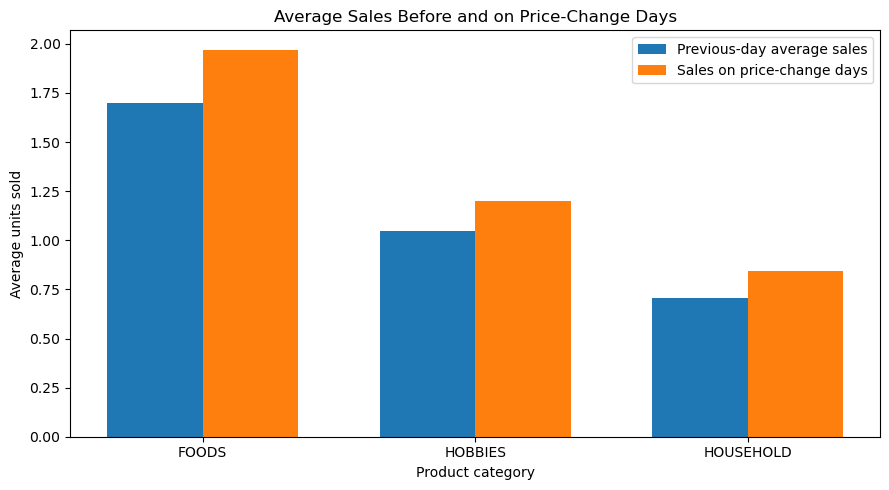

In [172]:
import matplotlib.pyplot as plt
import numpy as np

categories = category_price_analysis["cat_id"]

x = np.arange(len(categories))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    category_price_analysis["average_previous_sales"],
    width,
    label="Previous-day average sales"
)

plt.bar(
    x + width / 2,
    category_price_analysis["average_sales"],
    width,
    label="Sales on price-change days"
)

plt.xticks(x, categories)
plt.xlabel("Product category")
plt.ylabel("Average units sold")
plt.title("Average Sales Before and on Price-Change Days")
plt.legend()
plt.tight_layout()
plt.savefig("avg_sale_before_after.png", dpi= 800, bbox_inches="tight")
plt.show()